# Random forest: Reliance volatility forecast

Part of the ML Portfolio Model Zoo. Educational purposes only.

Forecast Reliance Industries' volatility over the next 20 trading days from what is known at today's close, using **real** prices from Yahoo Finance. This notebook walks through the data audit first, then the model and an honest comparison with simpler forecasts. Everything reuses `train.py`, so the notebook and the site share one pipeline.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

pd.set_option('display.width', 160)

## 1. Download

`load_raw()` reads the cached `data/raw_yahoo.csv`, or downloads it from Yahoo Finance the first time (`load_raw(refresh=True)` forces a fresh download). Tickers: `RELIANCE.NS`, `^NSEI` (Nifty 50) and `^INDIAVIX` (India VIX).

In [2]:
raw = load_raw()
print(raw.shape)
raw['Close'].tail()

(2930, 18)


Ticker,RELIANCE.NS,^INDIAVIX,^NSEI
Date,,,
2026-11-06,1320.000000,17.469999,25030.349609
2026-11-09,1324.400024,17.420000,25044.650391
2026-11-11,1335.400024,17.559999,25255.050781
2026-11-12,1339.699951,16.620001,25299.349609
2026-11-13,1339.699951,15.500000,25144.300781


## 2. Check for missing data and bad values

The index and VIX have no close on some days Reliance traded (holidays, special sessions). Forward-filling would invent zero returns and understate volatility, so these days are dropped.

In [3]:
close = raw['Close']
print(close.isna().sum())
close[close.isna().any(axis=1)].head(10)

Ticker
RELIANCE.NS     0
^INDIAVIX      20
^NSEI           9
dtype: int64


Ticker,RELIANCE.NS,^INDIAVIX,^NSEI
Date,,,
2015-01-01,202.959000,15.03,NaN
2015-04-15,211.130859,14.62,NaN
2016-01-01,232.091934,14.26,NaN
2016-08-12,236.766449,13.77,NaN
2018-01-01,415.907104,13.35,NaN
2019-01-01,512.483459,15.33,NaN
2019-10-27,655.690857,NaN,NaN
2020-01-01,690.138306,NaN,12182.5
2020-11-14,924.061096,NaN,NaN


In [4]:
stock_high, stock_low = raw[('High', TICKERS['stock'])], raw[('Low', TICKERS['stock'])]
vol = raw[('Volume', TICKERS['stock'])]
print('zero-volume days:', list(vol.index[vol == 0].date))
print('zero or inverted high-low range:', int((stock_high <= stock_low).sum()))
print('duplicate dates:', raw.index.duplicated().sum(), '  non-positive prices:', int((close <= 0).sum().sum()))

zero-volume days: [datetime.date(2025, 3, 18), datetime.date(2026, 1, 15)]
zero or inverted high-low range: 2
duplicate dates: 0   non-positive prices: 0


## 3. Clean, build features, look for outliers

`prepare()` aligns the dates, computes range-based (Parkinson) volatility features and the next-20-day volatility target, and applies the rules in the README. For a volatility model the extreme days are the signal, so outliers are flagged and kept.

In [5]:
data, audit = prepare(raw)
for note in audit.notes:
    print('-', note)
print()
audit.counts

- 26 days dropped because a series had no value
- 1 days dropped for zero volume and 0 for a zero or inverted high-low range
- 20 days flagged as stock-specific outliers (|robust z| > 5) and kept
- 75 feature values capped to the form's ranges (7 features)



{'raw_rows': 2930,
 'first_date': '2015-01-01',
 'last_date': '2026-11-13',
 'duplicate_dates': 0,
 'non_positive_prices': 0,
 'missing_close': {'stock': 0, 'market': 9, 'vix': 20},
 'dropped_missing': 26,
 'dropped_zero_volume': 1,
 'dropped_bad_range': 0,
 'flagged_outliers': 20,
 'largest_abs_return_pct': 14.7,
 'dropped_warmup_or_horizon': 145,
 'capped_to_form_range': {'vol_5d_pct': 5,
  'vol_20d_pct': 12,
  'return_20d_pct': 20,
  'drawdown_pct': 3,
  'volume_ratio': 3,
  'market_vol_20d_pct': 20,
  'india_vix': 12},
 'rows_used': 2758}

In [6]:
print('Flagged as stock-specific outliers (kept):')
audit.flagged.round(2)

Flagged as stock-specific outliers (kept):


,stock,market,residual_z
Date,,,
2017-02-22,10.96,0.21,10.7
2017-02-27,4.75,-0.48,5.3
2018-10-08,5.77,0.31,5.5
2019-08-13,9.69,-1.65,11.5
2020-03-09,-12.34,-4.90,-6.9
2020-03-25,14.72,6.62,7.5
2020-03-26,-1.48,3.89,-5.6
2020-04-22,10.20,2.29,7.7
2020-04-24,3.36,-1.71,5.3


In [7]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
vol_5d_pct,2758.0,21.23,9.38,7.04,15.85,19.28,23.94,100.00
vol_20d_pct,2758.0,21.80,7.88,8.89,17.36,20.28,23.99,80.00
vol_60d_pct,2758.0,22.23,7.00,12.13,18.41,21.32,24.13,61.09
return_20d_pct,2758.0,1.51,7.43,-25.00,-3.31,0.71,5.95,30.00
drawdown_pct,2758.0,-8.11,6.19,-40.00,-11.99,-7.29,-3.11,0.00
volume_ratio,2758.0,1.01,0.40,0.34,0.75,0.92,1.16,4.00
market_vol_20d_pct,2758.0,13.87,7.08,5.03,9.58,12.14,15.66,60.00
india_vix,2758.0,16.47,5.81,9.15,13.00,15.19,18.28,60.00
next_20d_volatility_pct,2758.0,21.84,8.04,8.89,17.38,20.30,24.07,89.06


## 4. Why the target is a ratio

The first attempt predicted the volatility level directly. Volatility levels change between market regimes (the training years include the 2020 crash; the test years are calmer), and a forest cannot predict outside what it has seen. Predicting the *ratio* to the 60-day level is more stable. The same forest, both ways:

In [8]:
n_train = int(len(data) * 0.75)
x, y = data[COLUMNS], data[TARGET]
x_train, x_test = x.iloc[:n_train], x.iloc[n_train + HORIZON:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train + HORIZON:]

level = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=SEED, n_jobs=-1).fit(x_train, y_train)
ratio = RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=80, random_state=SEED, n_jobs=-1).fit(
    x_train, np.log(y_train / x_train[SCALE_COLUMN]))

print(f"mean volatility: train {y_train.mean():.1f}%  test {y_test.mean():.1f}%")
print(f"forest on the level  RMSE {np.sqrt(mean_squared_error(y_test, level.predict(x_test))):.2f}")
print(f"forest on the ratio  RMSE {np.sqrt(mean_squared_error(y_test, x_test[SCALE_COLUMN] * np.exp(ratio.predict(x_test)))):.2f}")

mean volatility: train 23.0%  test 18.3%
forest on the level  RMSE 9.01


forest on the ratio  RMSE 3.93


## 5. Train and evaluate

Chronological split with a 20-day gap. `train_and_evaluate()` also picks the forest's depth and leaf size with a time-aware cross-validation on the training data only, exports to ONNX and asserts that onnxruntime reproduces scikit-learn.

In [9]:
result = train_and_evaluate()
m = result.metrics
print(f"train {m['train_period']}  ({m['n_train']} days)")
print(f"test  {m['test_period']}  ({m['n_test']} days)")
print('chosen:', m['best_params'])
print(f"ONNX vs sklearn max abs diff: {m['onnx_max_abs_diff']:.1e}")

train 2015-07-08 to 2023-12-18  (2068 days)
test  2024-01-18 to 2026-10-14  (670 days)
chosen: {'max_depth': 3, 'min_samples_leaf': 80}
ONNX vs sklearn max abs diff: 2.6e-06


In [10]:
rows = {
    'Training-period average': m['train_mean'], 'Last 60 days volatility': m['persistence_60d'],
    'Last 20 days volatility': m['persistence_20d'], 'Linear regression': m['linear'],
    'Linear regression, forest setup': m['linear_same_setup'],
    'Random forest': {k: m[k] for k in ('r2', 'rmse', 'mae')},
}
pd.DataFrame(rows).T.round(2)

,r2,rmse,mae
Training-period average,-1.62,5.92,5.21
Last 60 days volatility,-0.39,4.31,3.28
Last 20 days volatility,-0.36,4.26,3.18
Linear regression,-0.11,3.86,3.18
"Linear regression, forest setup",-0.17,3.95,3.14
Random forest,-0.16,3.93,3.12


R² is negative for every method because the test period was unusually calm (little variation, lower average than training), so any error in the level is heavily penalised. RMSE and MAE make the comparison clearer: the forest beats repeating recent volatility by about 8% and ties a straight line.

In [11]:
print('Permutation importance (drop in test R2 when the column is shuffled):')
result.importance.sort_values(ascending=False).round(3)

Permutation importance (drop in test R2 when the column is shuffled):


vol_60d_pct           0.091
drawdown_pct          0.030
india_vix             0.024
volume_ratio          0.023
return_20d_pct        0.000
vol_5d_pct           -0.003
market_vol_20d_pct   -0.004
vol_20d_pct          -0.020
dtype: float64

## 6. Charts

The same charts the site shows, written to a temporary folder.

Reliance's 20-day range-based volatility next to India VIX. The spikes are real (March 2020, the 2024 election result, single-day shocks); red circles mark stock-specific outlier days, which were kept.


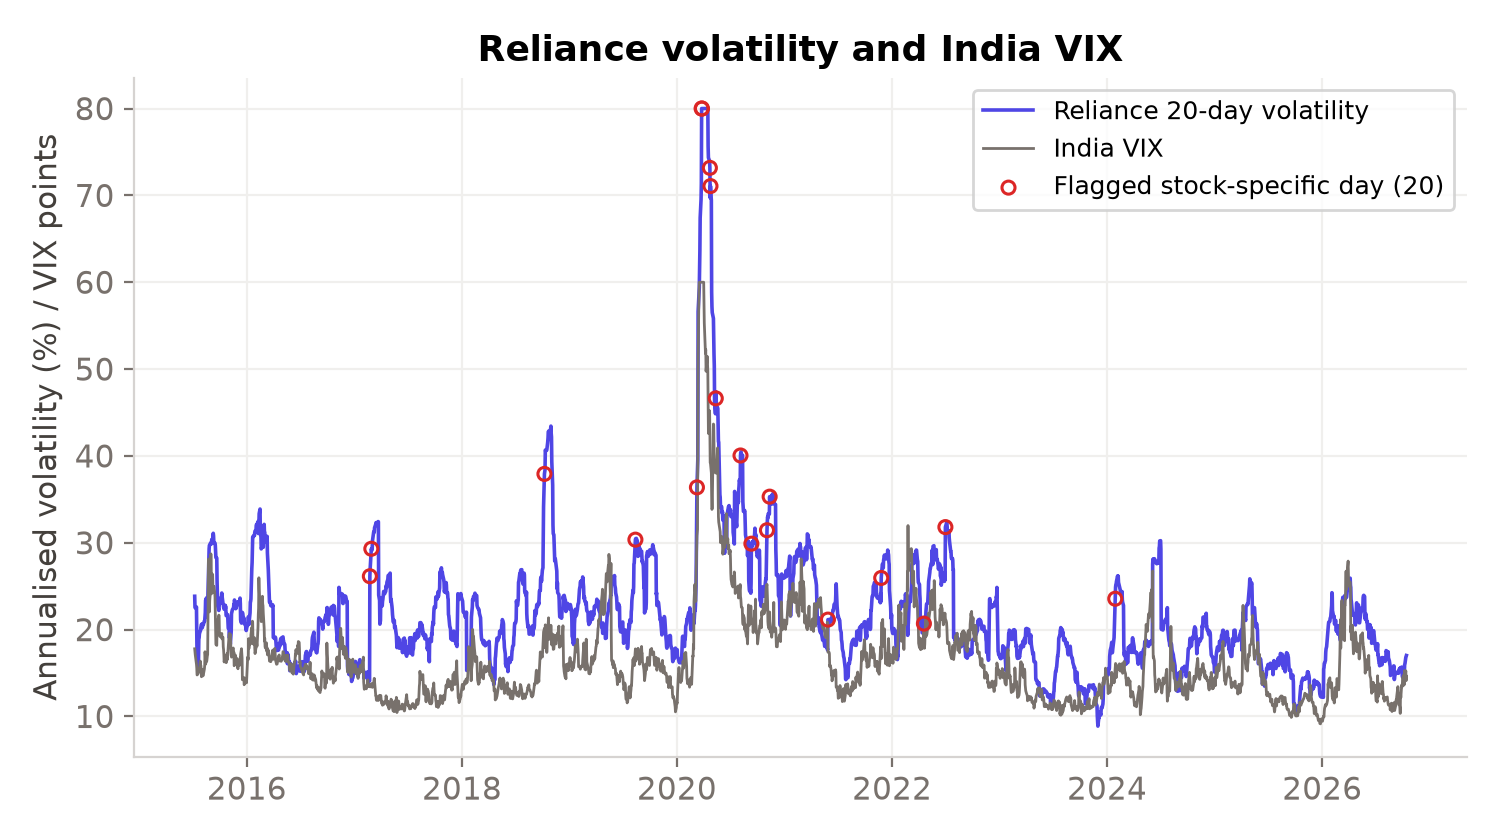

The forest's forecast against what happened over the next 20 days, on the most recent days held out from training. It tracks the broad level but cannot foresee sudden shocks.


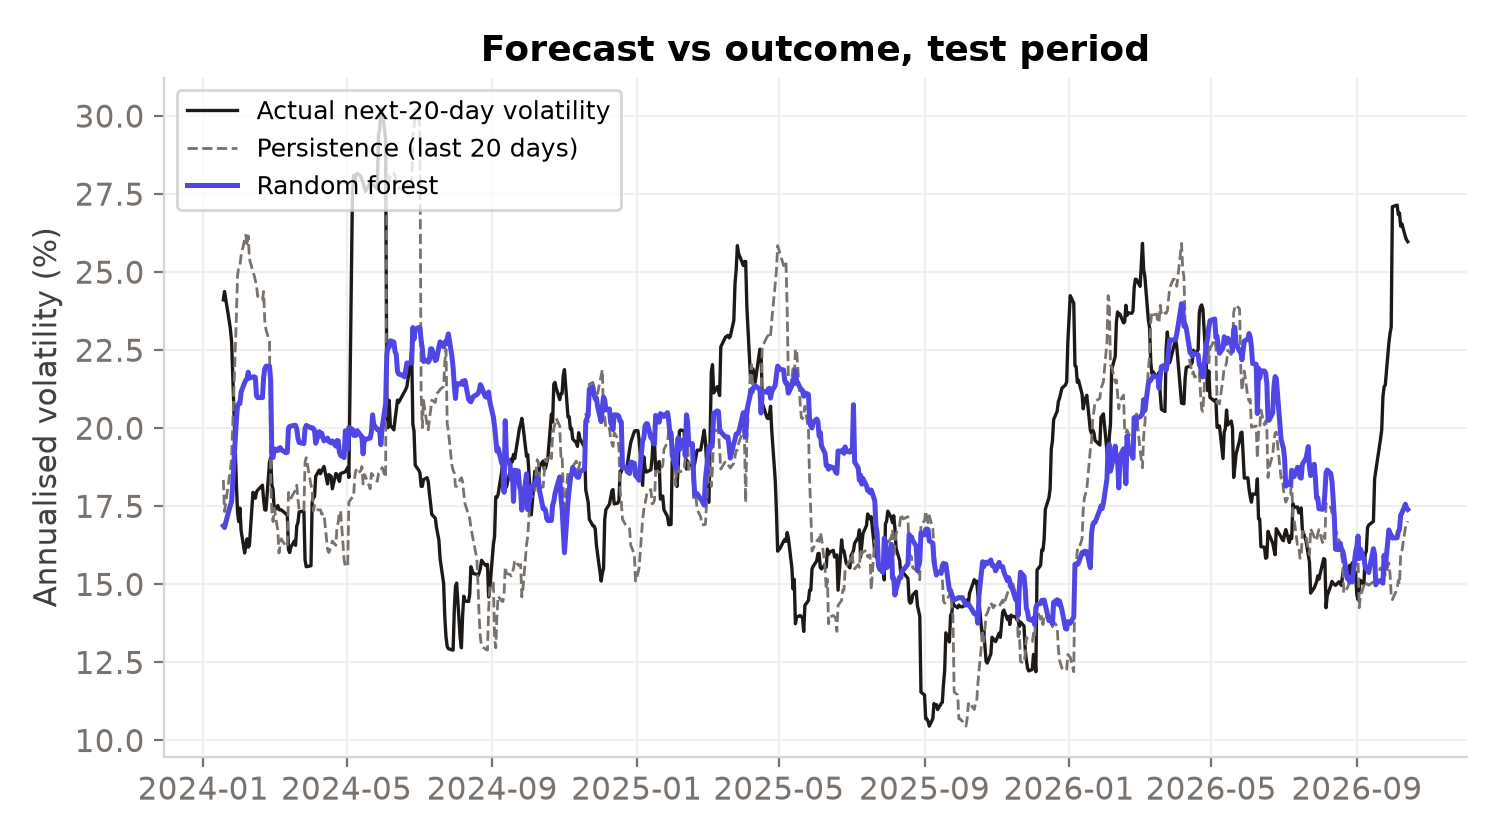

Predicted against actual 20-day volatility on the test period. Forecasts are compressed towards the middle: the extremes are not predicted.


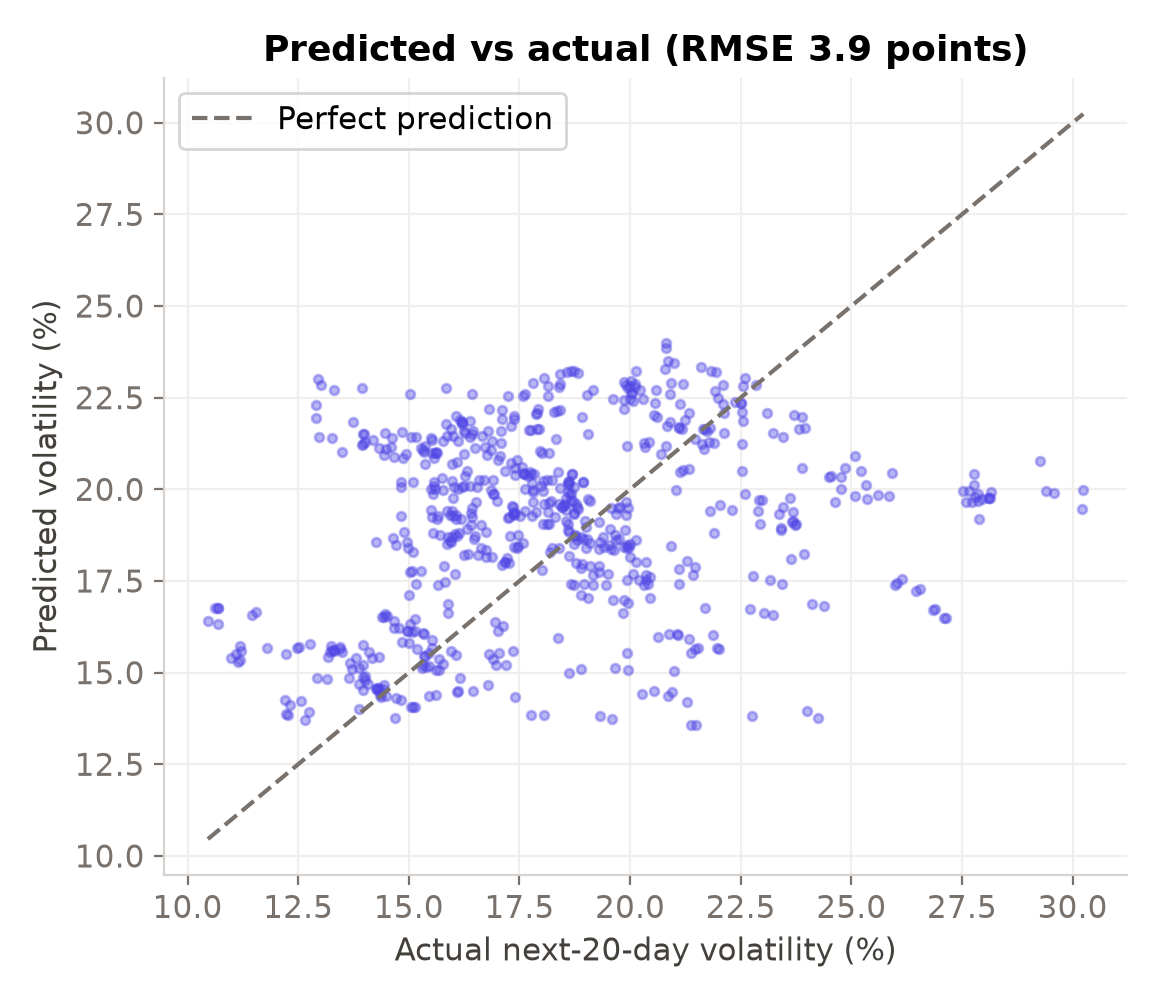

Test-period error for five forecasts. Simply carrying today's volatility forward is a hard baseline to beat; the forest and a straight line both do a little better.


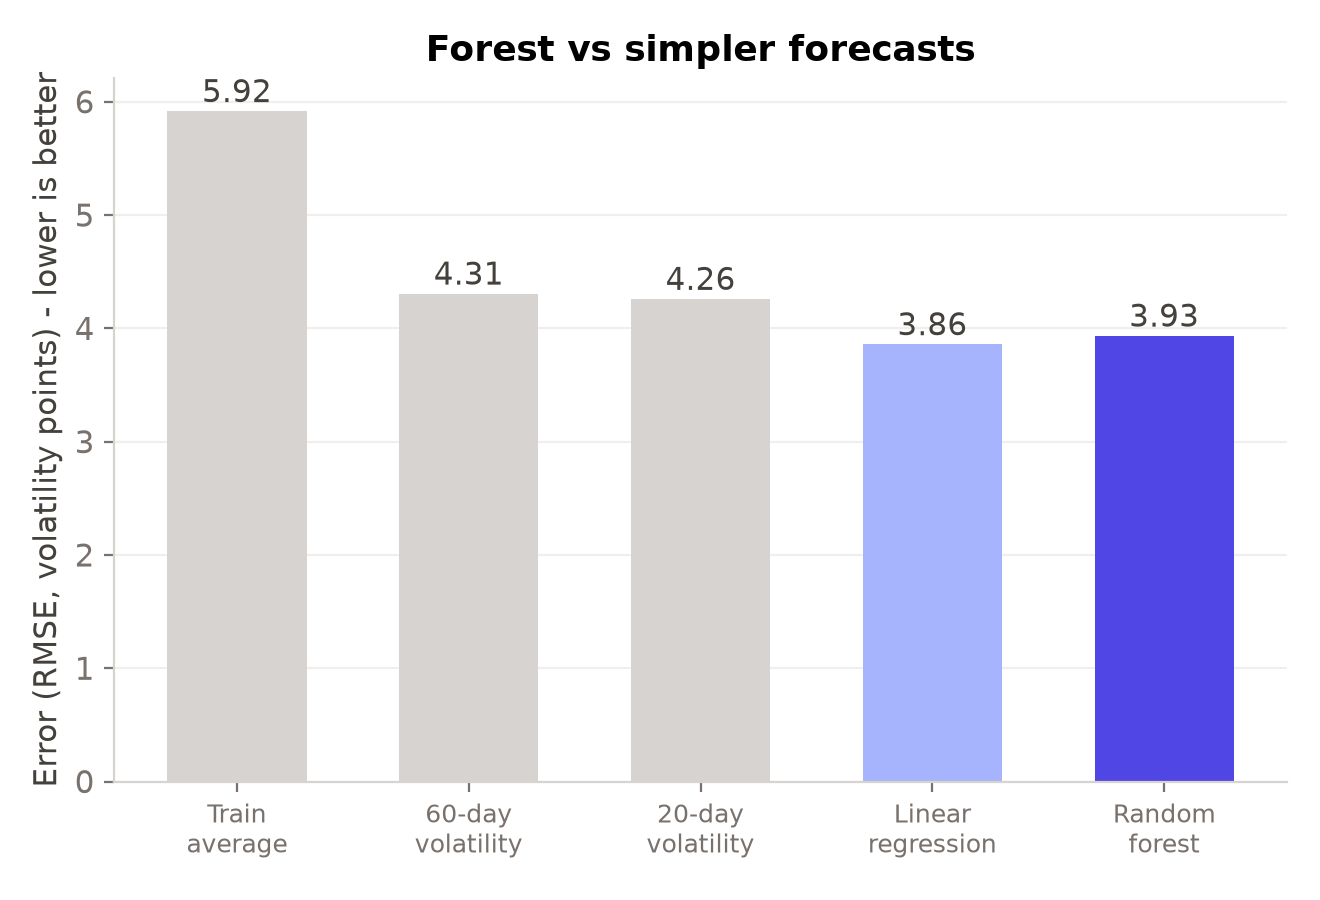

Which inputs the forest relies on, measured by how much accuracy falls when each is scrambled. The 60-day level anchors the forecast; bars below zero are inputs that add noise on the test period.


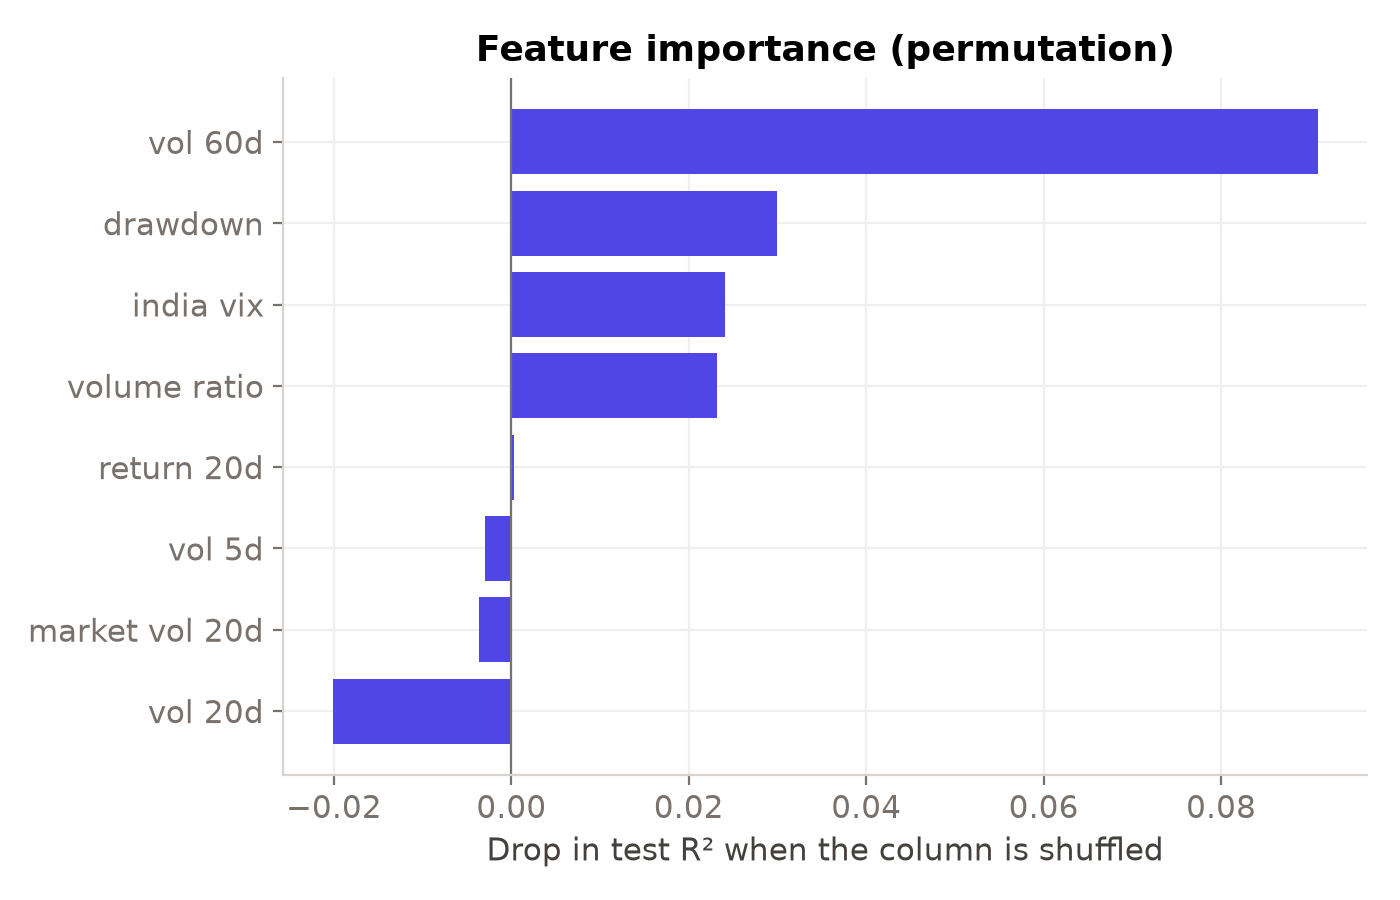

Predicted volatility as the last 20 days get more volatile, other inputs held at typical values. Both models stay close to the 60-day level instead of carrying a spike forward, which is why simply repeating the last 20 days does worse.


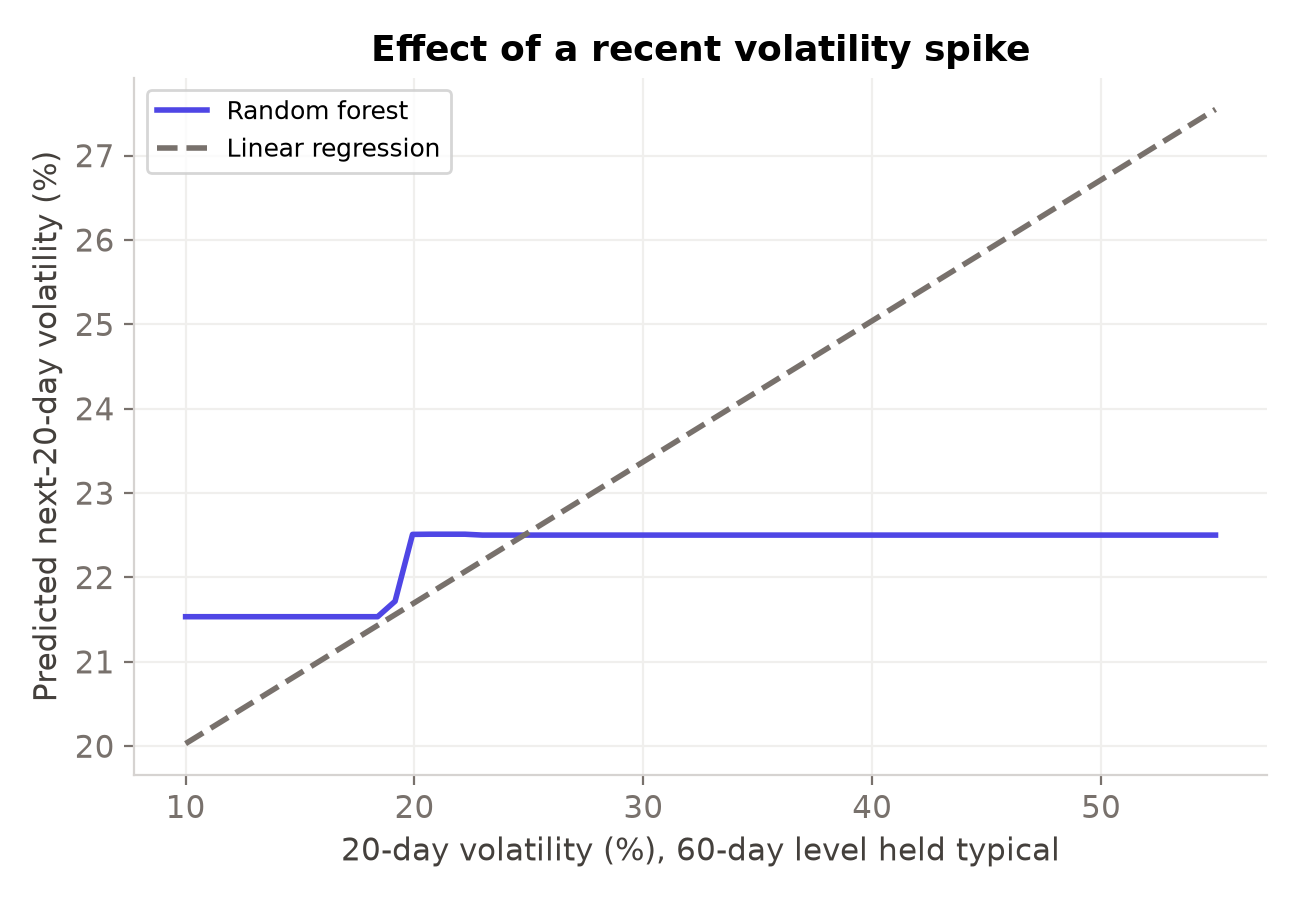

In [12]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## 7. Predict with the exported ONNX model

In [13]:
example = pd.DataFrame([PRESETS[1]['values']])[COLUMNS]
print('After a sharp sell-off ->', f"{onnx_predict(result.model_bytes, example)[0]:.1f}% expected volatility")

After a sharp sell-off -> 26.2% expected volatility


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app.